In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
ruta = '/content/drive/MyDrive/mineria/new_online_shoppers_intention.csv'
df = pd.read_csv(ruta)
print("Dimensiones:", df.shape)
display(df.head())

Dimensiones: (12205, 22)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,Browser,Region,TrafficType,VisitorType,Weekend,Revenue,Avg_Tiempo_Producto,Total_paginasVisitadas,Duracion_Total,Trimestre
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,...,1,1,1,Returning_Visitor,False,False,0.000000,1,0.000000,1
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,...,2,1,2,Returning_Visitor,False,False,21.333333,2,64.000000,1
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,...,1,9,3,Returning_Visitor,False,False,0.000000,1,0.000000,1
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,...,2,2,4,Returning_Visitor,False,False,0.888889,2,2.666667,1
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,...,3,1,4,Returning_Visitor,True,False,57.045455,10,627.500000,1


# Estandarizacion de variables

In [ ]:
numericas = ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration','ProductRelated', 'ProductRelated_Duration','BounceRates','ExitRates',
                    'PageValues','Avg_Tiempo_Producto', 'Total_paginasVisitadas', 'Duracion_Total']

    Se seleccionaron 12 características numéricas relacionadas con la cantidad de páginas visitadas, el tiempo de navegación, las tasas de rebote y salida.
    Las variables seleccionadas permiten analizar diferentes comportamientos de los visitantes dentro del sitio web.

In [ ]:
df_cluster = df[numericas].copy()

In [ ]:
# Seleccionamos solo las variables numéricas para escalar, o asegúrate de codificar las categóricas previamente
columnas_numericas = df_cluster.select_dtypes(include=[np.number]).columns

scaler = StandardScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(df_cluster[numericas]),
    columns=columnas_numericas,
    index=df_cluster.index
)
X_scaled.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,Avg_Tiempo_Producto,Total_paginasVisitadas,Duracion_Total
0,-0.702302,-0.460019,-0.398824,-0.246257,-0.696218,-0.628793,3.969402,3.434394,-0.318962,-1.010569,-0.726926,-0.647550
1,-0.702302,-0.460019,-0.398824,-0.246257,-0.673793,-0.595451,-0.450137,1.268054,-0.318962,-0.389027,-0.705479,-0.616235
2,-0.702302,-0.460019,-0.398824,-0.246257,-0.696218,-0.628793,3.969402,3.434394,-0.318962,-1.010569,-0.726926,-0.647550
3,-0.702302,-0.460019,-0.398824,-0.246257,-0.673793,-0.627404,0.654748,2.134590,-0.318962,-0.984671,-0.705479,-0.646245
4,-0.702302,-0.460019,-0.398824,-0.246257,-0.494387,-0.301889,-0.008183,0.184884,-0.318962,0.651438,-0.533898,-0.340522


# Entrenar Kmeans

In [ ]:
kmeans = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
kmeans.fit(X_scaled)

KMeans(n_clusters=3, n_init=10, random_state=42)

Para hacer una prueba inicial inicializamos k-means con 3 clusters

In [ ]:
df_km1= df.copy()
df_km1['Cluster'] = kmeans.labels_
df_km1.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,Region,TrafficType,VisitorType,Weekend,Revenue,Avg_Tiempo_Producto,Total_paginasVisitadas,Duracion_Total,Trimestre,Cluster
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,...,1,1,Returning_Visitor,False,False,0.000000,1,0.000000,1,2
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,...,1,2,Returning_Visitor,False,False,21.333333,2,64.000000,1,0
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,...,9,3,Returning_Visitor,False,False,0.000000,1,0.000000,1,2
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,...,2,4,Returning_Visitor,False,False,0.888889,2,2.666667,1,2
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,...,1,4,Returning_Visitor,True,False,57.045455,10,627.500000,1,0


In [ ]:
df_km1['Cluster'].value_counts()


,count
Cluster,
0,9952
1,1331
2,922


In [ ]:
"""
for v in numericas:
  plt.figure(figsize=(10, 5))

  sns.boxplot(
      data=df_km1,
      x="Cluster",
      y=v,
      hue="Cluster",
      palette="Blues"
  )

  plt.title(f"Distribución del {v} por clúster")
  plt.xlabel("Clúster K-Means")
  plt.ylabel(v)
  plt.show()
  print("-"*50)
  """

'\nfor v in numericas:\n  plt.figure(figsize=(10, 5))\n\n  sns.boxplot(\n      data=df_km1,\n      x="Cluster",\n      y=v,\n      hue="Cluster",\n      palette="Blues"\n  )\n\n  plt.title(f"Distribución del {v} por clúster")\n  plt.xlabel("Clúster K-Means")\n  plt.ylabel(v)\n  plt.show()\n  print("-"*50)\n  '

In [ ]:
# comparacion de varios valores de k
valores_k = range(2, 9)
filas_k = []
for k in valores_k:
    modelo = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    etiquetas = modelo.fit_predict(X_scaled)
    print(etiquetas)
    #WCSS - metodo de codo, inercia que tanto se mueve los datos
    filas_k.append({"k": k, "WCSS": modelo.inertia_,
                    "Silhouette": silhouette_score(X_scaled, etiquetas, sample_size=min(1500, len(X_scaled)), random_state=RANDOM_STATE)})
resultado_k = pd.DataFrame(filas_k)
display(resultado_k.round(3))

[1 1 1 ... 1 1 1]
[2 0 2 ... 0 0 0]
[1 0 1 ... 0 0 0]
[2 3 2 ... 3 3 3]
[1 4 1 ... 4 4 4]
[2 1 2 ... 1 1 1]
[2 0 2 ... 0 0 0]


,k,WCSS,Silhouette
0,2,113284.817,0.491
1,3,93533.024,0.456
2,4,82210.638,0.399
3,5,75191.810,0.392
4,6,68376.688,0.370
5,7,62818.772,0.370
6,8,57642.293,0.357


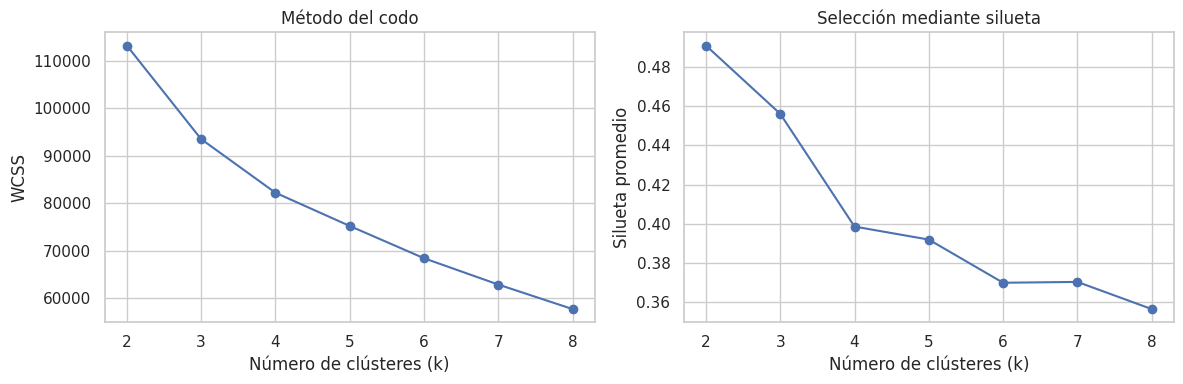

In [ ]:
# Método del codo y Silhouette
# Pruebas de validacion
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Empaquetar las variables y etiquetas de cada gráfica
metricas = [
    ("WCSS", "WCSS", "Método del codo"),
    ("Silhouette", "Silueta promedio", "Selección mediante silueta")
]

for ax, (columna, ylabel, titulo) in zip(axes, metricas):
    ax.plot(resultado_k["k"], resultado_k[columna], "o-")
    ax.set(xlabel="Número de clústeres (k)", ylabel=ylabel, title=titulo)

plt.tight_layout()
plt.show()

La silueta más alta se obtiene con K = 2 (0.491), seguida de K = 3 (0.456). Aunque el WCSS sigue bajando al aumentar K, se conserva K = 3 porque genera tres perfiles interpretables: navegación moderada, intensiva y breve con alta salida. Esta decisión se documenta explícitamente para no confundirla con una elección basada solo en la silueta.

## Pruebas con 3 clusters

In [ ]:
k_elegido = 3
kmeans = KMeans(n_clusters=k_elegido, random_state=RANDOM_STATE, n_init=10)
kmeans.fit(X_scaled)
df_km = df.copy()
df_km['Cluster'] = kmeans.labels_
display(df_km.head())
df_km['Cluster'].value_counts()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,Region,TrafficType,VisitorType,Weekend,Revenue,Avg_Tiempo_Producto,Total_paginasVisitadas,Duracion_Total,Trimestre,Cluster
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,...,1,1,Returning_Visitor,False,False,0.000000,1,0.000000,1,2
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,...,1,2,Returning_Visitor,False,False,21.333333,2,64.000000,1,0
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,...,9,3,Returning_Visitor,False,False,0.000000,1,0.000000,1,2
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,...,2,4,Returning_Visitor,False,False,0.888889,2,2.666667,1,2
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,...,1,4,Returning_Visitor,True,False,57.045455,10,627.500000,1,0


,count
Cluster,
0,9952
1,1331
2,922


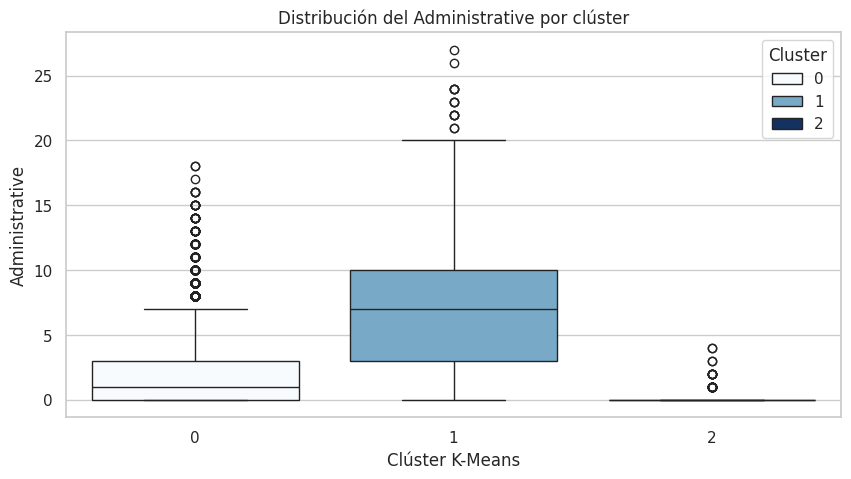

--------------------------------------------------


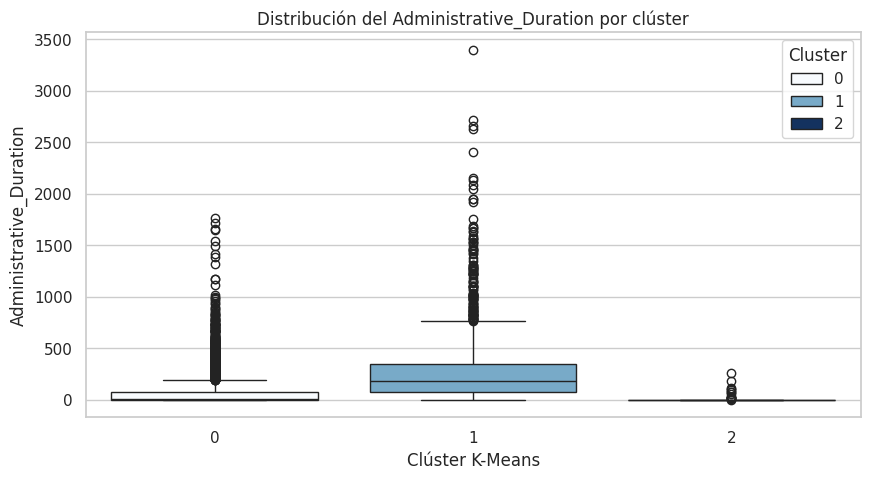

--------------------------------------------------


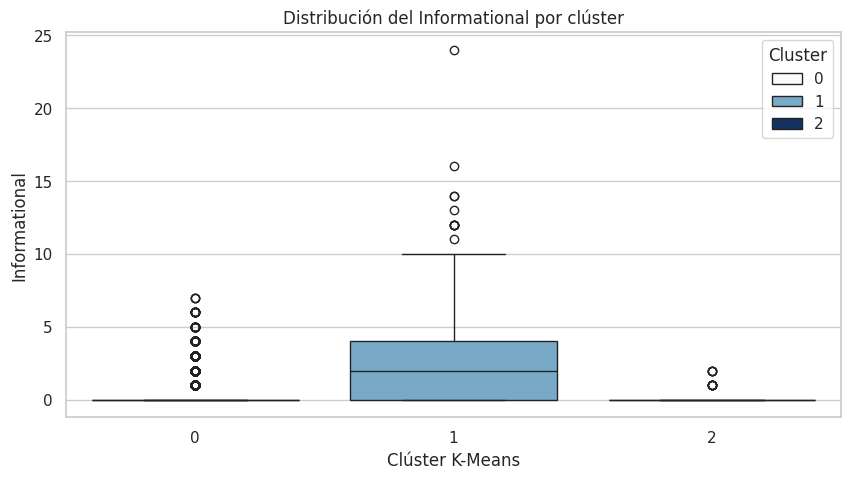

--------------------------------------------------


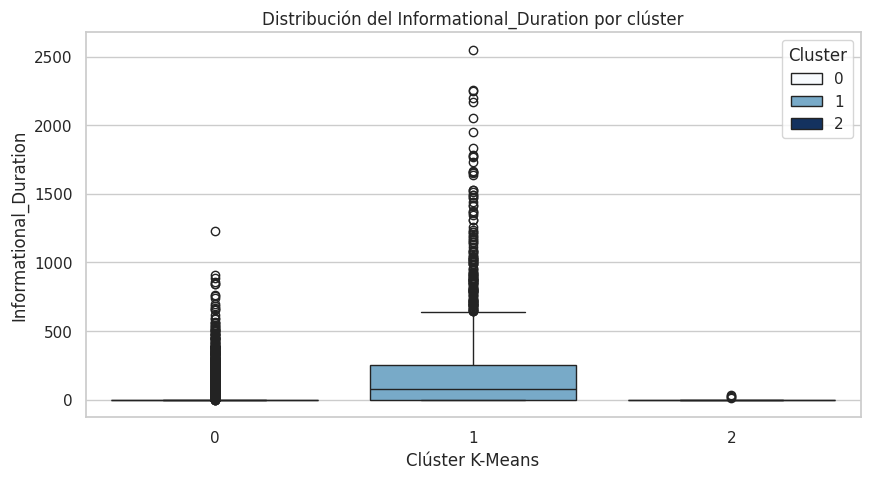

--------------------------------------------------


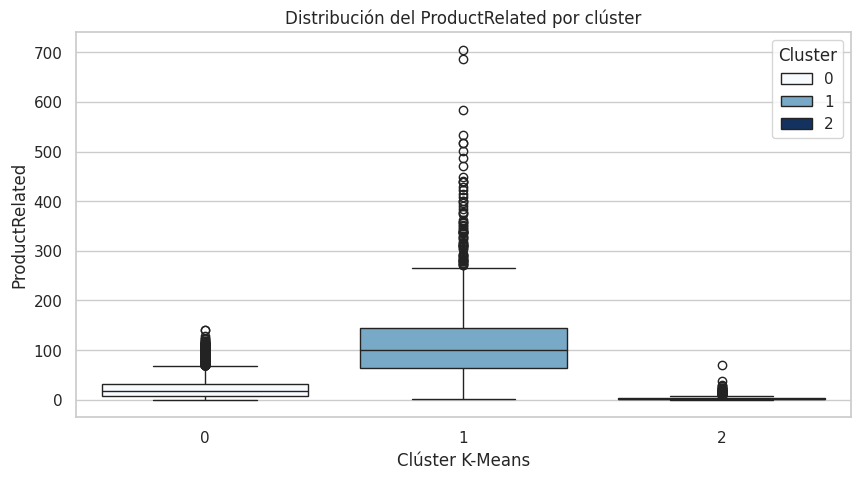

--------------------------------------------------


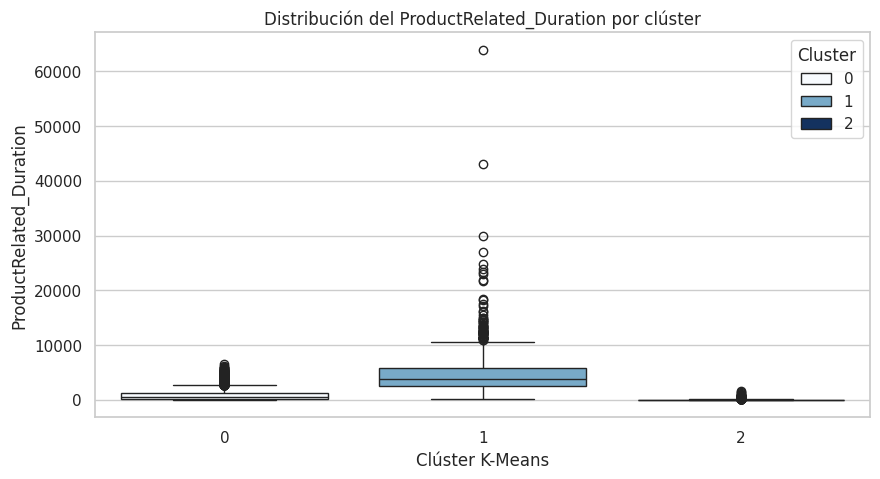

--------------------------------------------------


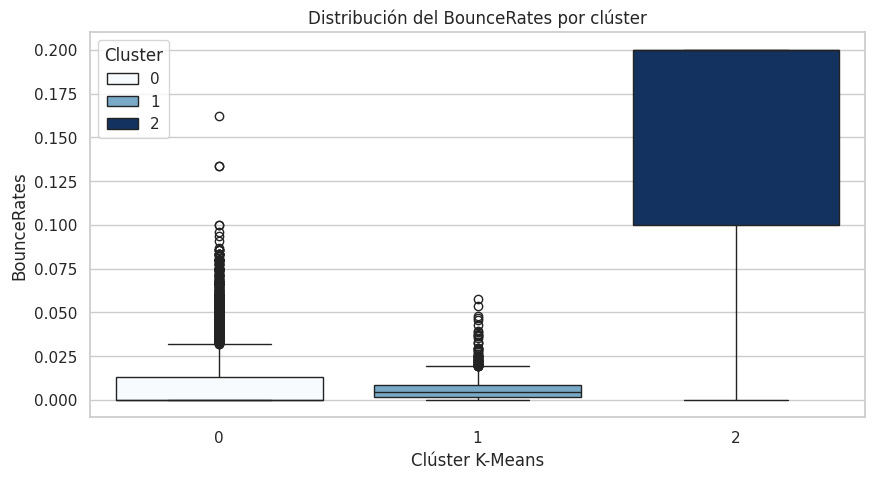

--------------------------------------------------


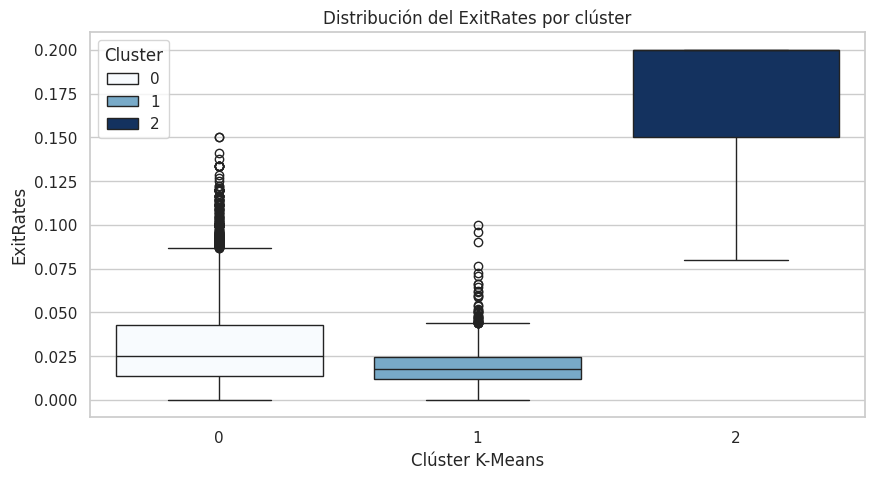

--------------------------------------------------


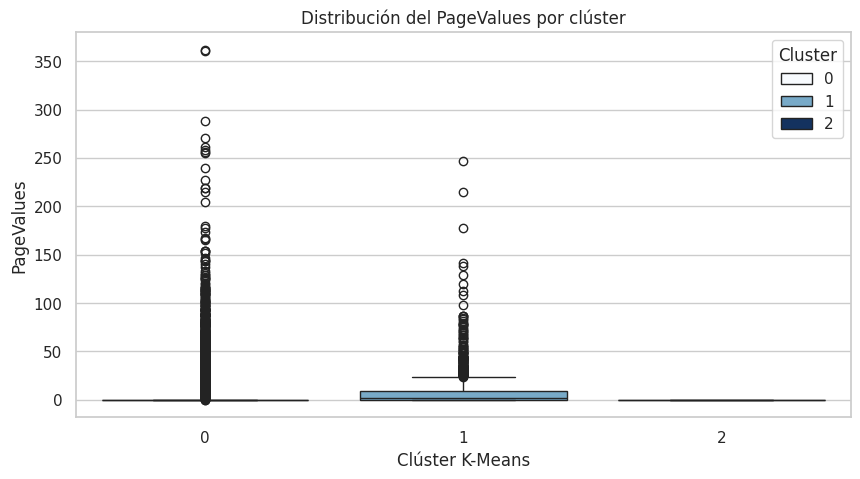

--------------------------------------------------


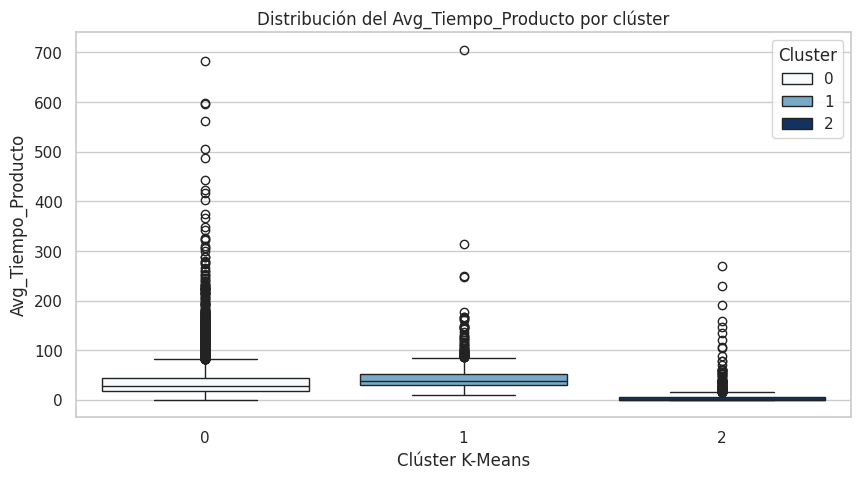

--------------------------------------------------


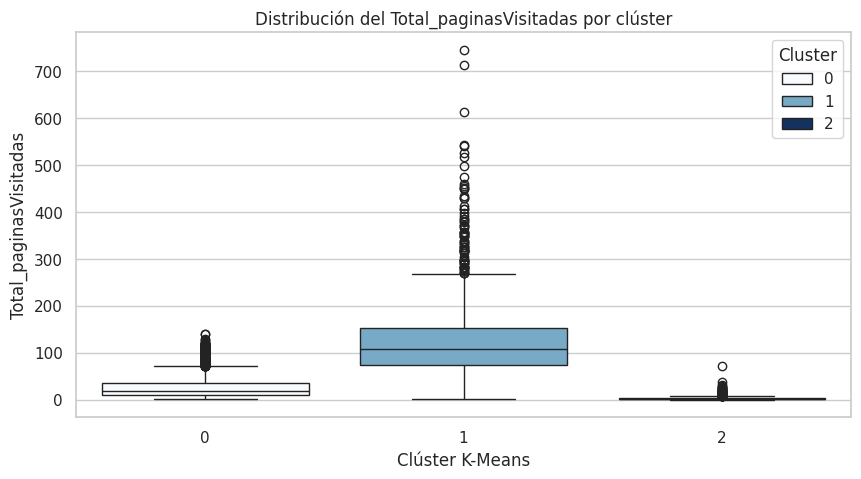

--------------------------------------------------


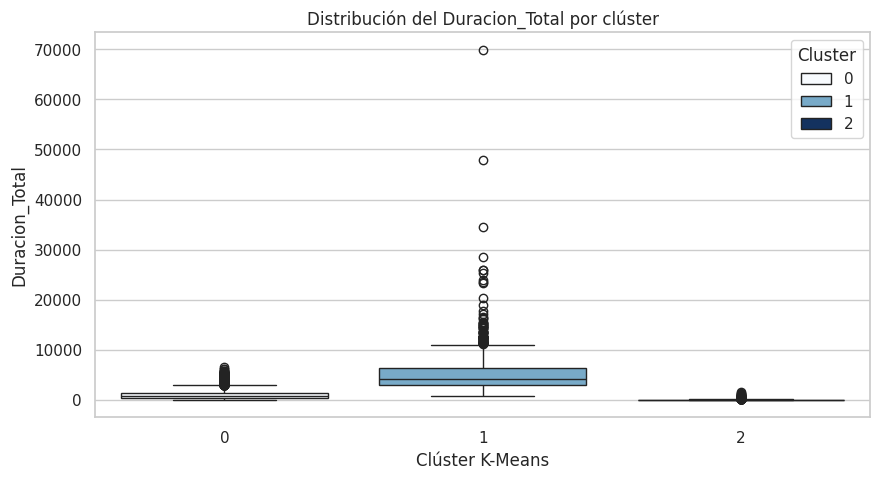

--------------------------------------------------


In [ ]:
for v in numericas:
  plt.figure(figsize=(10, 5))

  sns.boxplot(
      data=df_km,
      x="Cluster",
      y=v,
      hue="Cluster",
      palette="Blues"
  )

  plt.title(f"Distribución del {v} por clúster")
  plt.xlabel("Clúster K-Means")
  plt.ylabel(v)
  plt.show()
  print("-"*50)

**Observaciones (K = 3):**

- El clúster 1 presenta los valores más altos en cantidad de páginas visitadas y tiempo de navegación, y las tasas más bajas de rebote y salida. Es el grupo de navegación intensiva.
- El clúster 0 tiene valores intermedios: navega más que el clúster 2 pero menos que el clúster 1, y concentra a la mayoría de las sesiones.
- El clúster 2 registra las tasas más altas de `BounceRates` y `ExitRates` y casi no pasa tiempo en el sitio; corresponde a navegación breve con alta salida.

In [ ]:
# Visualizacion de los centroides
centroides_originales = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=X_scaled.columns)
centroides_originales.index.name = 'CLuster'
centroides_originales.round(2)

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,Avg_Tiempo_Producto,Total_paginasVisitadas,Duracion_Total
CLuster,,,,,,,,,,,,
0,1.91,61.03,0.30,14.06,23.33,851.20,0.01,0.03,6.10,36.07,25.53,926.30
1,7.11,291.87,2.45,214.41,117.31,4675.93,0.01,0.02,8.94,43.78,126.87,5182.21
2,0.06,1.17,0.02,0.10,3.29,47.75,0.16,0.18,-0.00,6.67,3.37,49.01


In [ ]:
pca_cent = PCA(n_components=2)
# se entrena con los datos escalados
pca_cent.fit(X_scaled)

prod_pca = pca_cent.transform(X_scaled)
centroides_df = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=X_scaled.columns
)

# PCA tambien ayuda a entrenar variables

cent_pca = pca_cent.transform(centroides_df)
centroides_df

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,Avg_Tiempo_Producto,Total_paginasVisitadas,Duracion_Total
0,-0.127940,-0.116144,-0.167194,-0.146804,-0.195561,-0.185347,-0.248104,-0.208902,0.008135,0.040210,-0.200744,-0.194322
1,1.433275,1.184473,1.519505,1.269899,1.912091,1.807190,-0.313142,-0.483486,0.160354,0.265049,1.972638,1.888042
2,-0.684716,-0.453439,-0.385220,-0.245558,-0.644848,-0.603919,3.129926,2.952234,-0.318962,-0.816156,-0.676169,-0.623568


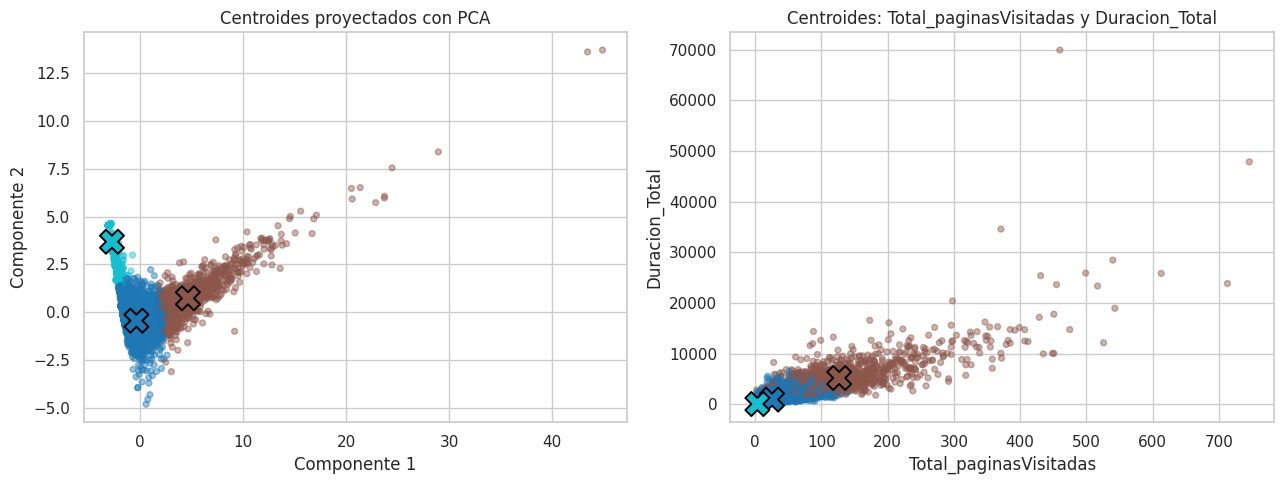

In [ ]:
  #Graficar los centroides con PCA
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

data_plots = [
    (prod_pca, cent_pca, 'Centroides proyectados con PCA', 'Componente 1', 'Componente 2'),
    (df[['Total_paginasVisitadas', 'Duracion_Total']].values, centroides_originales[['Total_paginasVisitadas', 'Duracion_Total']].values,
     'Centroides: Total_paginasVisitadas y Duracion_Total', 'Total_paginasVisitadas', 'Duracion_Total')
]

for ax, (obs, cents, title, xlab, ylab) in zip(axes, data_plots):
    ax.scatter(obs[:, 0], obs[:, 1], c=df_km['Cluster'], cmap='tab10', s=18, alpha=0.45)

    ax.scatter(cents[:, 0], cents[:, 1], marker='X', c=np.arange(k_elegido), cmap='tab10',
               s=300, edgecolor='black', linewidth=1.4)

    ax.set(title=title, xlabel=xlab, ylabel=ylab)

plt.tight_layout()
plt.show()

Con las variables

,Sesiones,Compras,Tasa_Conversion
Cluster,,,
0,9952,1503,15.10
1,1331,399,29.98
2,922,6,0.65


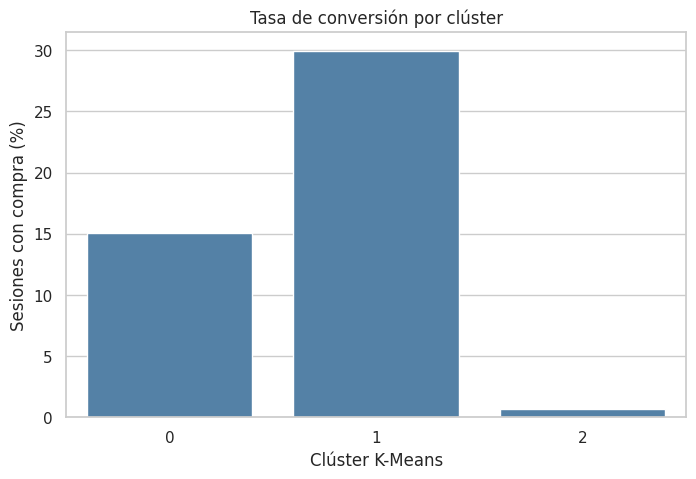

In [ ]:


# Comparar el porcentaje de compras entre clústeres
conversion_clusters = df_km.groupby("Cluster")["Revenue"].agg(
    Sesiones="count",
    Compras="sum",
    Tasa_Conversion="mean"
)

conversion_clusters["Tasa_Conversion"] *= 100

display(conversion_clusters.round(2))

plt.figure(figsize=(8, 5))

sns.barplot(
    x=conversion_clusters.index,
    y=conversion_clusters["Tasa_Conversion"],
    color="steelblue"
)

plt.title("Tasa de conversión por clúster")
plt.xlabel("Clúster K-Means")
plt.ylabel("Sesiones con compra (%)")
plt.show()



**Observaciones (conversión con K = 3):**

- Clúster 0: 9,952 sesiones, 1,503 compras, conversión 15.10 %.
- Clúster 1: 1,331 sesiones, 399 compras, conversión 29.98 %. Es el grupo con mayor tasa de conversión.
- Clúster 2: 922 sesiones, 6 compras, conversión 0.65 %. Casi no convierte y presenta las mayores tasas de rebote y salida.
- `Revenue` no se usó para entrenar K-Means; se consultó después solo para interpretar los segmentos.

# Pruebas para 4 clusters

In [ ]:
k_elegido = 4
kmeans = KMeans(n_clusters=k_elegido, random_state=RANDOM_STATE, n_init=10)
kmeans.fit(X_scaled)
df_km = df.copy()
df_km['Cluster'] = kmeans.labels_
display(df_km.head())
df_km['Cluster'].value_counts()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,Region,TrafficType,VisitorType,Weekend,Revenue,Avg_Tiempo_Producto,Total_paginasVisitadas,Duracion_Total,Trimestre,Cluster
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,...,1,1,Returning_Visitor,False,False,0.000000,1,0.000000,1,1
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,...,1,2,Returning_Visitor,False,False,21.333333,2,64.000000,1,0
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,...,9,3,Returning_Visitor,False,False,0.000000,1,0.000000,1,1
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,...,2,4,Returning_Visitor,False,False,0.888889,2,2.666667,1,1
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,...,1,4,Returning_Visitor,True,False,57.045455,10,627.500000,1,0


,count
Cluster,
0,8728
3,2308
1,899
2,270


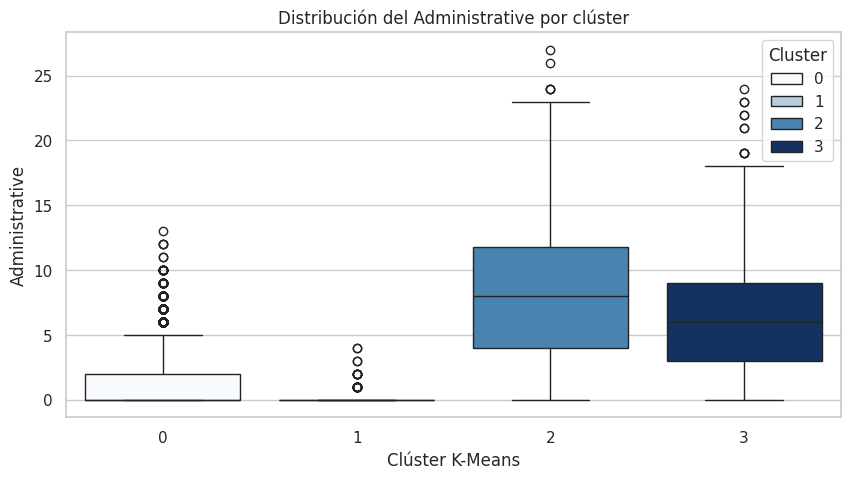

--------------------------------------------------


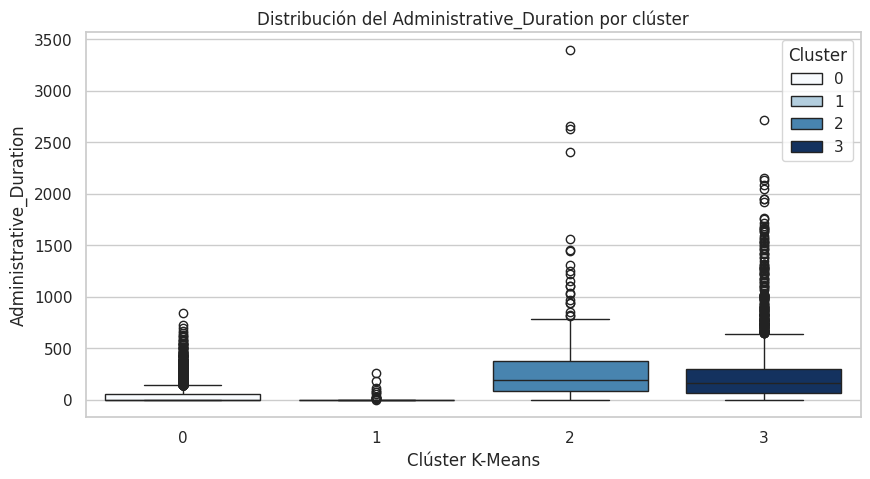

--------------------------------------------------


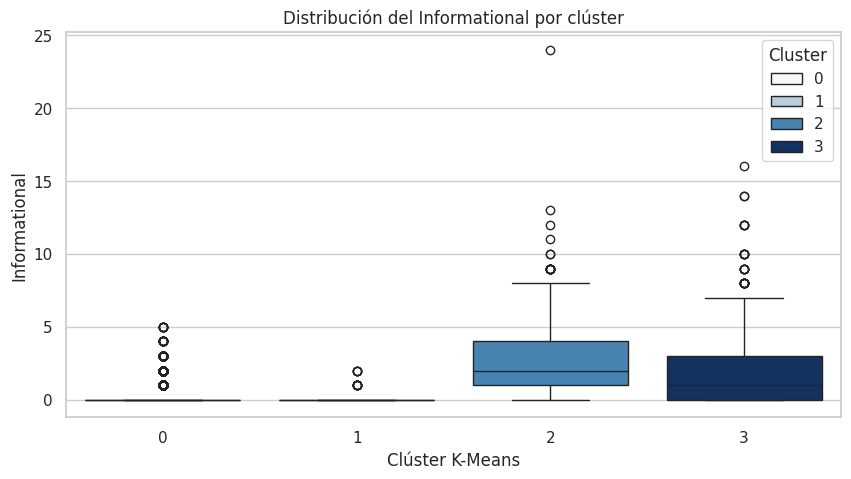

--------------------------------------------------


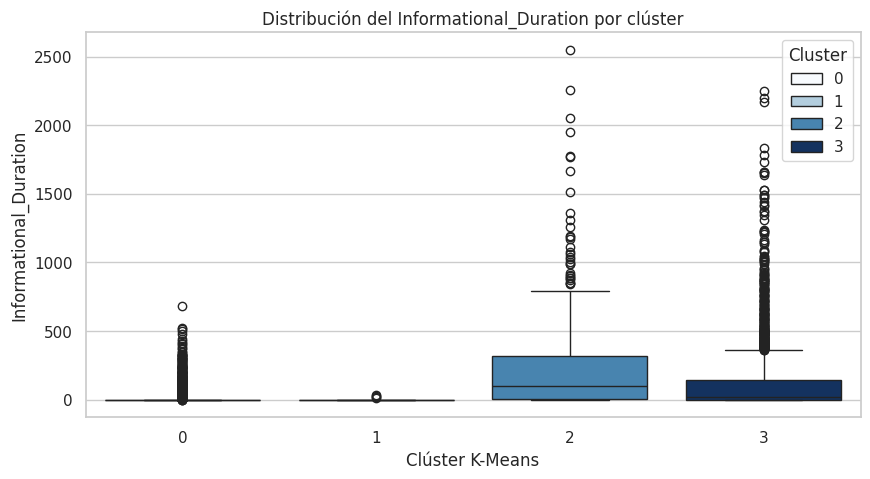

--------------------------------------------------


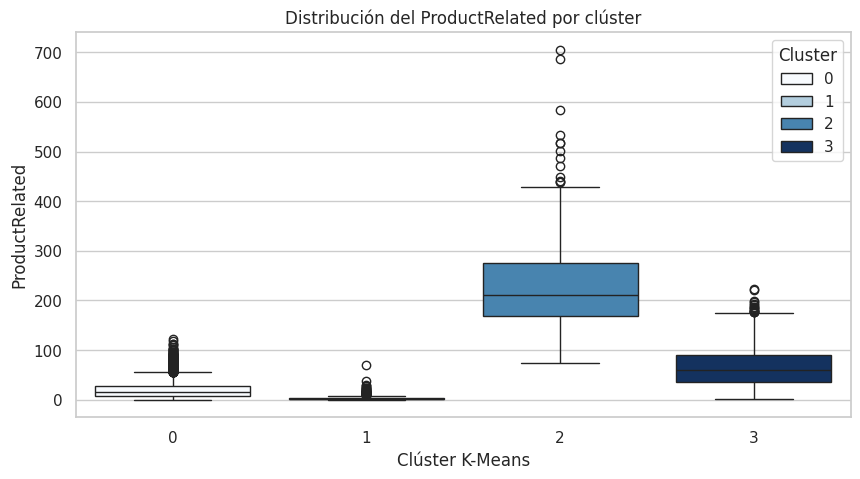

--------------------------------------------------


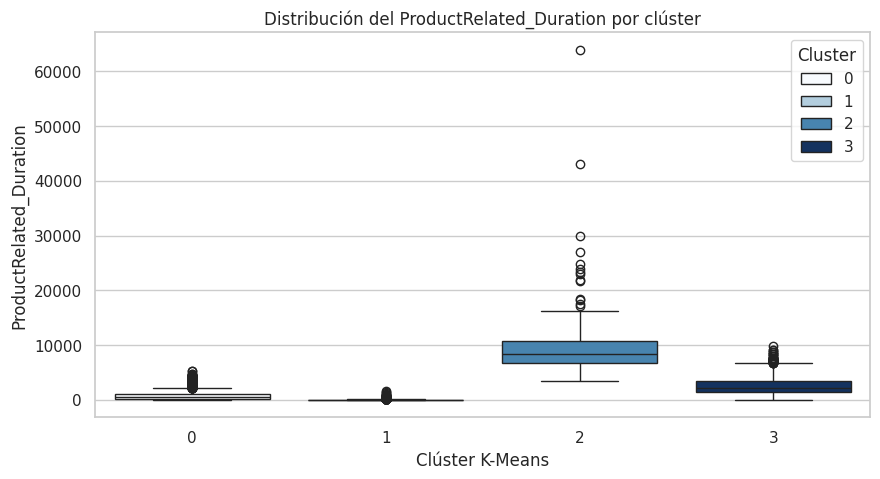

--------------------------------------------------


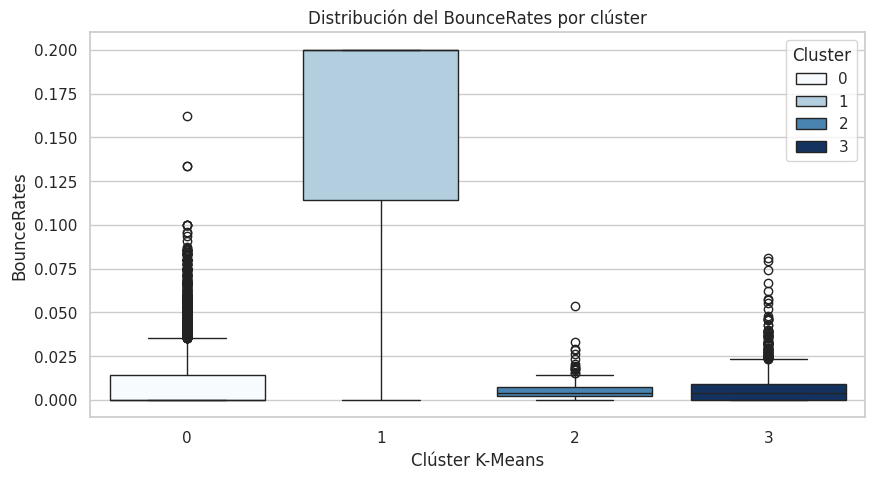

--------------------------------------------------


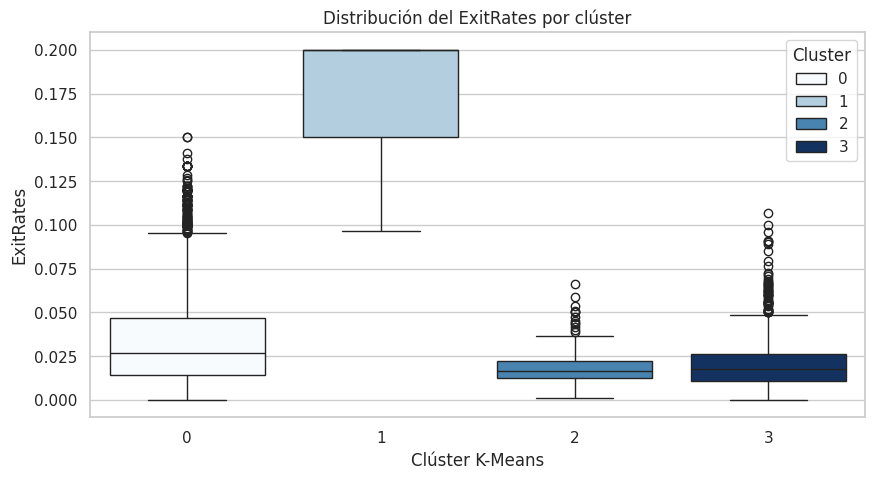

--------------------------------------------------


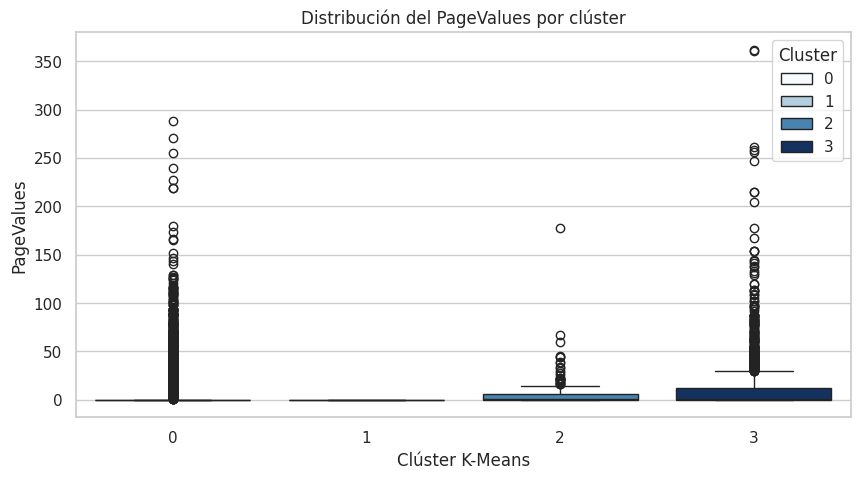

--------------------------------------------------


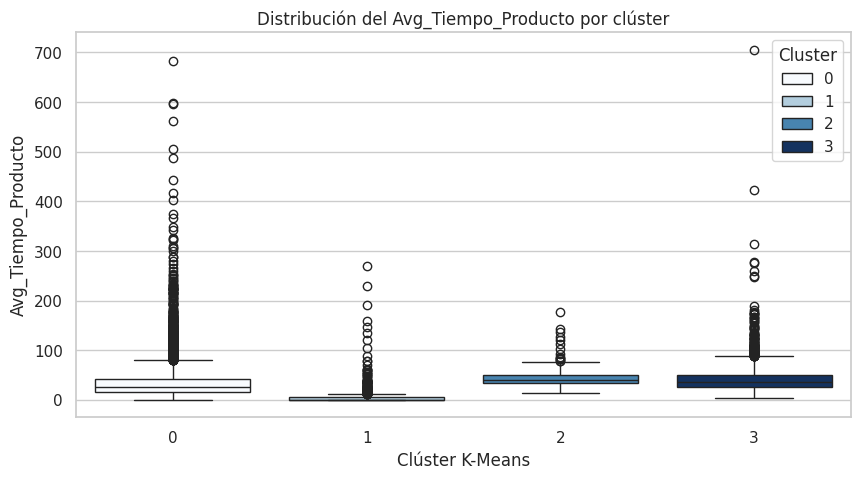

--------------------------------------------------


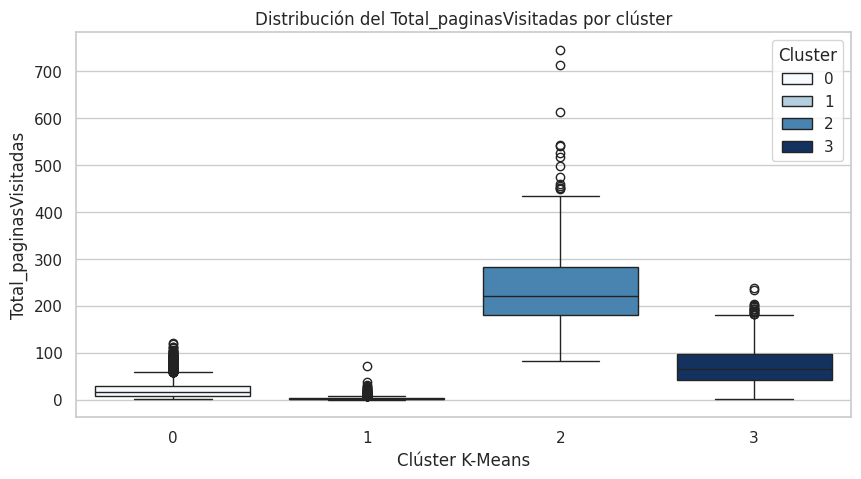

--------------------------------------------------


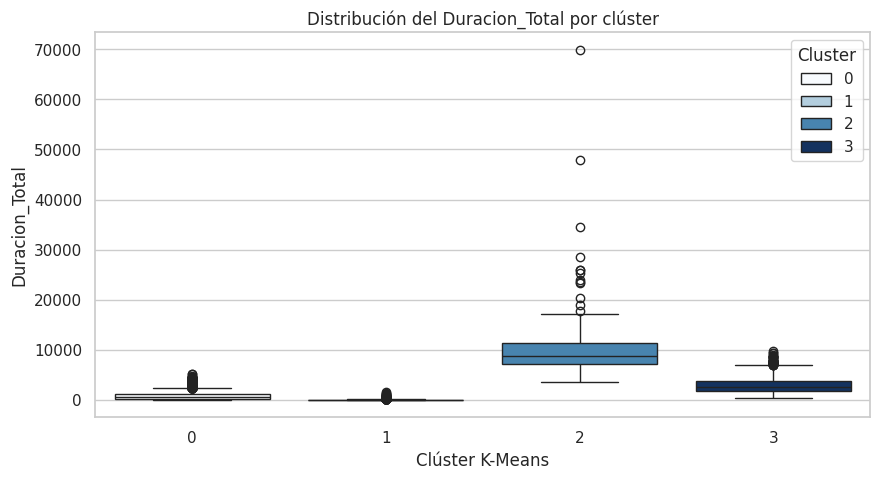

--------------------------------------------------


In [ ]:
for v in numericas:
  plt.figure(figsize=(10, 5))

  sns.boxplot(
      data=df_km,
      x="Cluster",
      y=v,
      hue="Cluster",
      palette="Blues"
  )

  plt.title(f"Distribución del {v} por clúster")
  plt.xlabel("Clúster K-Means")
  plt.ylabel(v)
  plt.show()
  print("-"*50)

**Observaciones (K = 4):**

- El clúster 2 agrupa 270 sesiones y tiene la mayor conversión (34.07 %), aunque es un segmento muy pequeño.
- El clúster 3 tiene 2,308 sesiones y 26.43 % de conversión; representa navegación intensiva.
- El clúster 0 reúne 8,728 sesiones con 13.75 % de conversión (navegación moderada).
- El clúster 1 tiene 899 sesiones y apenas 0.67 % de conversión, con navegación breve y alta salida.
- K = 4 permite separar un perfil muy conversivo, pero se conserva K = 3 por ser más interpretable y porque la silueta no mejora (0.399 frente a 0.456).

In [ ]:
# Visualizacion de los centroides
centroides_originales = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=X_scaled.columns)
centroides_originales.index.name = 'CLuster'
centroides_originales.round(2)

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,Avg_Tiempo_Producto,Total_paginasVisitadas,Duracion_Total
CLuster,,,,,,,,,,,,
0,1.39,40.36,0.17,6.40,19.78,710.27,0.01,0.03,5.17,35.22,21.35,757.03
1,0.06,1.08,0.02,0.10,3.13,43.73,0.16,0.18,-0.00,6.20,3.21,44.91
2,8.26,312.07,3.02,273.41,233.16,9550.01,0.01,0.02,5.68,43.38,244.43,10135.49
3,6.10,242.04,1.67,127.84,66.11,2560.85,0.01,0.02,11.24,42.74,73.88,2930.74


In [ ]:
pca_cent = PCA(n_components=2)
# se entrena con los datos escalados
pca_cent.fit(X_scaled)

prod_pca = pca_cent.transform(X_scaled)
centroides_df = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=X_scaled.columns
)

# PCA tambien ayuda a entrenar variables

cent_pca = pca_cent.transform(centroides_df)
centroides_df

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,Avg_Tiempo_Producto,Total_paginasVisitadas,Duracion_Total
0,-0.283448,-0.232645,-0.262084,-0.201018,-0.274973,-0.258767,-0.235663,-0.167493,-0.041789,0.015525,-0.290396,-0.277146
1,-0.685268,-0.453941,-0.384872,-0.245540,-0.648373,-0.606012,3.176351,2.990654,-0.318962,-0.829895,-0.679570,-0.625577
2,1.777732,1.298256,1.967594,1.687081,4.510018,4.346406,-0.328718,-0.503242,-0.014390,0.253364,4.494116,4.311618
3,1.129624,0.903732,0.909823,0.657709,0.763895,0.705316,-0.307529,-0.472371,0.283673,0.234718,0.836153,0.786423


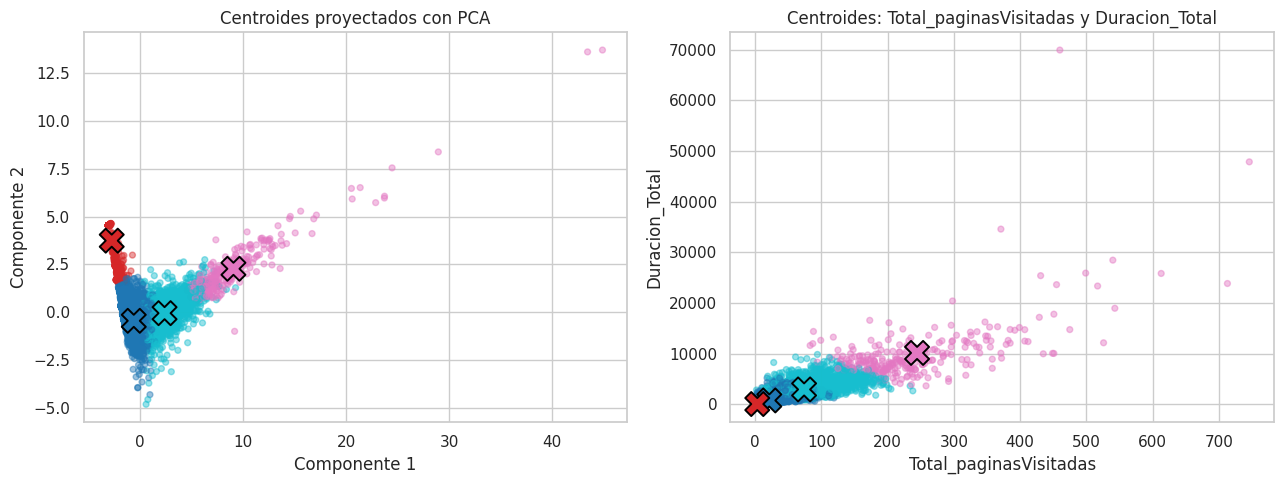

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

data_plots = [
    (prod_pca, cent_pca, 'Centroides proyectados con PCA', 'Componente 1', 'Componente 2'),
    (df[['Total_paginasVisitadas', 'Duracion_Total']].values, centroides_originales[['Total_paginasVisitadas', 'Duracion_Total']].values,
     'Centroides: Total_paginasVisitadas y Duracion_Total', 'Total_paginasVisitadas', 'Duracion_Total')
]

for ax, (obs, cents, title, xlab, ylab) in zip(axes, data_plots):
    ax.scatter(obs[:, 0], obs[:, 1], c=df_km['Cluster'], cmap='tab10', s=18, alpha=0.45)

    ax.scatter(cents[:, 0], cents[:, 1], marker='X', c=np.arange(k_elegido), cmap='tab10',
               s=300, edgecolor='black', linewidth=1.4)

    ax.set(title=title, xlabel=xlab, ylabel=ylab)

plt.tight_layout()
plt.show()

**Observaciones:**

PCA se utilizó únicamente para visualizar los clústeres en dos dimensiones; no intervino en el entrenamiento de K-Means. Al aumentar de 3 a 4 clústeres aparece un grupo pequeño en un extremo de la proyección, correspondiente al segmento más conversivo. Las componentes explican solo una parte de la varianza, por lo que la gráfica debe interpretarse con cautela.

,Sesiones,Compras,Tasa_Conversion
Cluster,,,
0,8728,1200,13.75
1,899,6,0.67
2,270,92,34.07
3,2308,610,26.43


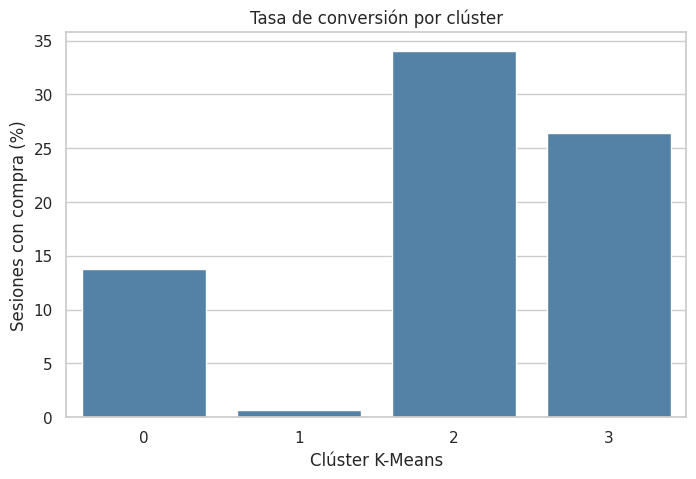

In [ ]:
# Comparar el porcentaje de compras entre clústeres
conversion_clusters = df_km.groupby("Cluster")["Revenue"].agg(
    Sesiones="count",
    Compras="sum",
    Tasa_Conversion="mean"
)

conversion_clusters["Tasa_Conversion"] *= 100

display(conversion_clusters.round(2))

plt.figure(figsize=(8, 5))

sns.barplot(
    x=conversion_clusters.index,
    y=conversion_clusters["Tasa_Conversion"],
    color="steelblue"
)

plt.title("Tasa de conversión por clúster")
plt.xlabel("Clúster K-Means")
plt.ylabel("Sesiones con compra (%)")
plt.show()

Al comparar con `Revenue`, K = 4 revela un segmento pequeño (270 sesiones) con 34.07 % de conversión, por encima del mejor grupo de K = 3 (29.98 %). Sin embargo, al dividir en cuatro grupos, la mayoría de las sesiones queda en el clúster 0 (8,728; 13.75 %) y el perfil de baja actividad se mantiene casi sin compras (0.67 %). Se prefiere K = 3 para el modelo final por simplicidad e interpretabilidad.